
# Esperimento dell’ago di Buffon – Notebook completo (MATLAB → Python)

Questo notebook contiene:
1. Visualizzazione geometrica degli aghi (stima diretta di π)
2. Funzione di probabilità teorica di Buffon
3. Simulazione Monte Carlo estesa
4. Fit e grafico finale in stile MATLAB



## 1. Visualizzazione geometrica degli aghi
Traduzione diretta del primo codice MATLAB.


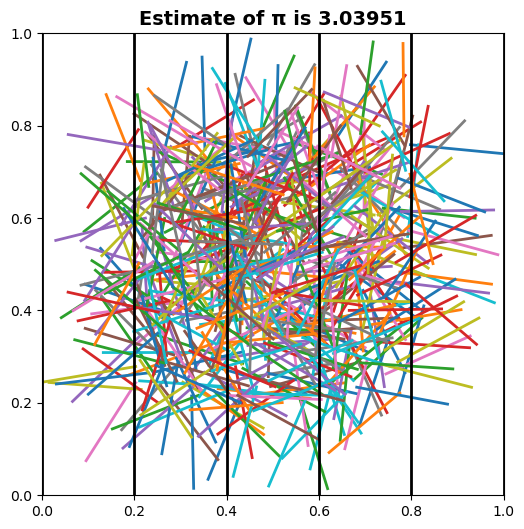

In [1]:

import numpy as np
import matplotlib.pyplot as plt

N = 500
L = 0.20

xb = L + np.random.rand(N) * (1 - 2*L)
yb = L + np.random.rand(N) * (1 - 2*L)

angs = np.random.rand(N) * 360.0

xe = xb + L * np.cos(np.deg2rad(angs))
ye = yb + L * np.sin(np.deg2rad(angs))

fig, ax = plt.subplots(figsize=(6, 6))

for i in range(N):
    ax.plot([xb[i], xe[i]], [yb[i], ye[i]], linewidth=2)

glines = np.arange(0, 1 + L, L)
for x in glines:
    ax.plot([x, x], [0, 1], 'k-', linewidth=2)

ax.set_aspect('equal')
ax.set_xlim(0, 1)
ax.set_ylim(0, 1)

n = np.sum(np.floor(xb / L) != np.floor(xe / L))
piEstimate = 2 * N / n

ax.set_title(f"Estimate of π is {piEstimate:.5f}", fontsize=14, fontweight='bold')
plt.show()



## 2. Funzione di probabilità teorica di Buffon
Traduzione del secondo codice MATLAB con `fplot`.


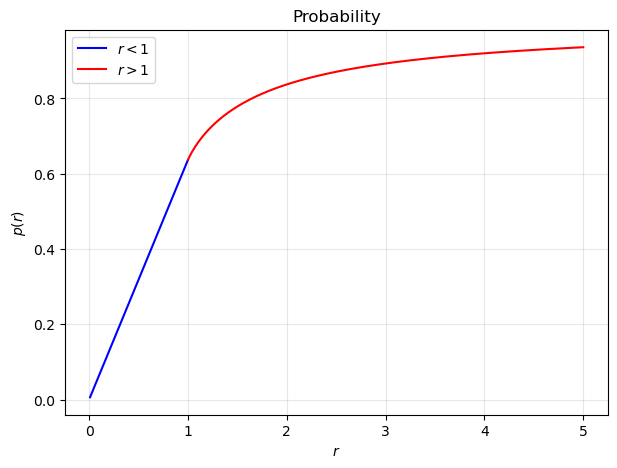

In [2]:

import numpy as np
import matplotlib.pyplot as plt

r1 = np.linspace(0.01, 1.0, 400)
r2 = np.linspace(1.0, 5.0, 400)

p1 = (2 / np.pi) * r1
p2 = (2 / np.pi) * (r2 - np.sqrt(r2**2 - 1) + np.pi/2 - np.arcsin(1/r2))

plt.figure(figsize=(7, 5))
plt.plot(r1, p1, 'b', label=r'$r < 1$')
plt.plot(r2, p2, 'r', label=r'$r > 1$')

plt.xlabel(r'$r$')
plt.ylabel(r'$p(r)$')
plt.title('Probability')
plt.legend()
plt.grid(alpha=0.3)
plt.show()



## 3. Simulazione Monte Carlo dell’esperimento di Buffon


In [3]:

import numpy as np
import matplotlib.pyplot as plt
from scipy.optimize import curve_fit

def buffon(N, l, d, dl=None, seed=None):
    rng = np.random.default_rng(seed)
    l = np.atleast_1d(l)
    p = np.zeros_like(l, dtype=float)

    for i, li in enumerate(l):
        x1 = 9 * rng.random(N) + 1
        y1 = 9 * rng.random(N) + 1
        theta = 2 * np.pi * rng.random(N)
        x2 = x1 + li * np.cos(theta)
        y2 = y1 + li * np.sin(theta)

        ymin = np.minimum(y1, y2)
        ymax = np.maximum(y1, y2)
        criterion = (np.ceil(ymin / d) <= np.floor(ymax / d))
        p[i] = np.sum(criterion) / N

    def model(pval, a, b):
        return a * pval + b

    if dl is not None:
        popt, pcov = curve_fit(model, p, l, sigma=dl, absolute_sigma=True)
    else:
        popt, pcov = curve_fit(model, p, l)

    dp = np.sqrt(np.diag(pcov))
    return p, popt, dp



## 4. Fit e grafico finale (stile MATLAB)


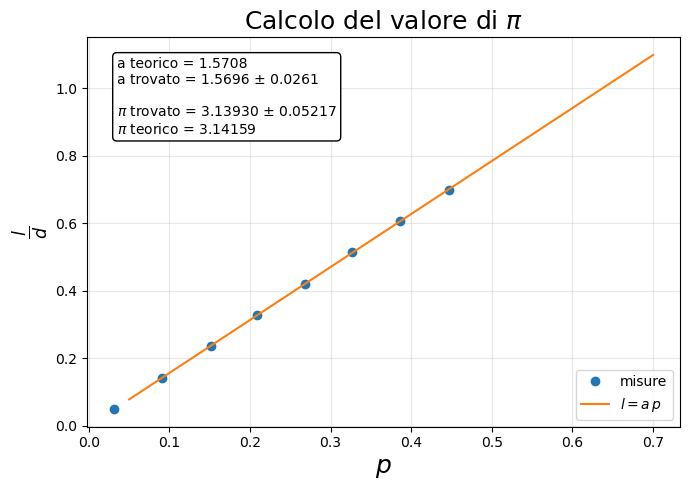

In [4]:

# Parametri
N = 200_000
d = 1.0
l_vals = np.linspace(0.05, 0.7, 8)
dl_vals = 0.01 * np.ones_like(l_vals)

p, pout, dp = buffon(N, l_vals, d, dl_vals, seed=0)

a, b = pout
da, db = dp

plt.figure(figsize=(7, 5))
plt.plot(p, l_vals/d, 'o', label='misure')

p_fit = np.linspace(0.05, 0.7, 300)
plt.plot(p_fit, (a*p_fit)/d, '-', label=r'$l = a\,p$')

plt.xlabel(r'$p$', fontsize=18)
plt.ylabel(r'$\frac{l}{d}$', fontsize=18)
plt.title(r'Calcolo del valore di $\pi$', fontsize=18)
plt.legend()

pi_est = 2*a/d
dpi_est = 2*da/d

txt = (
    f"a teorico = {np.pi/2:.4f}\n"
    f"a trovato = {a:.4f} ± {da:.4f}\n\n"
    f"$\pi$ trovato = {pi_est:.5f} ± {dpi_est:.5f}\n"
    f"$\pi$ teorico = {np.pi:.5f}"
)

plt.text(0.05, 0.95, txt, transform=plt.gca().transAxes,
         verticalalignment='top',
         bbox=dict(boxstyle='round', facecolor='white'))

plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()



## 5. Convergenza della stima di \(\pi\) al crescere di \(N\) (replica del blocco MATLAB con tic/toc)

Questo blocco ripete la stima per diversi numeri di lanci \(N\) e genera una figura per ciascun caso, come nel codice MATLAB.
> Nota pratica: \(N=10^8\) può richiedere parecchio tempo e memoria. Nel codice sotto è disattivato di default: abilitalo mettendo `RUN_HEAVY = True`.


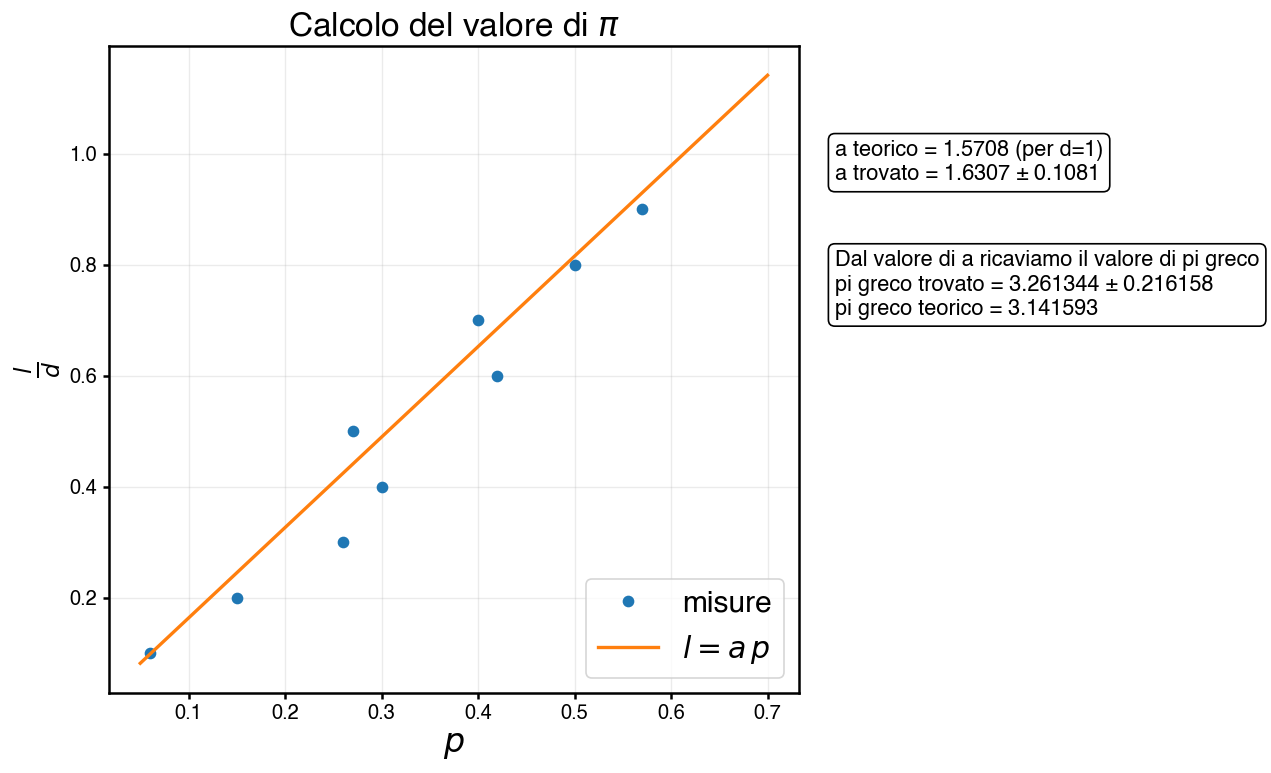

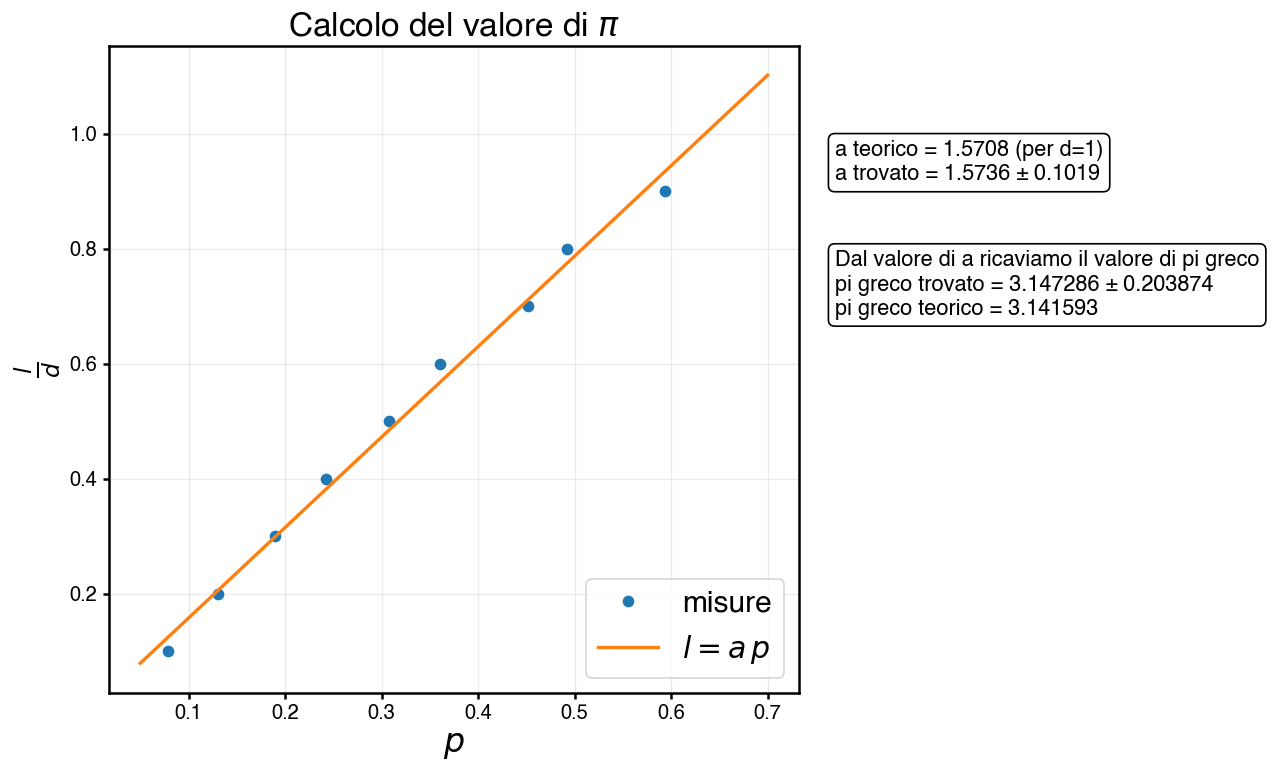

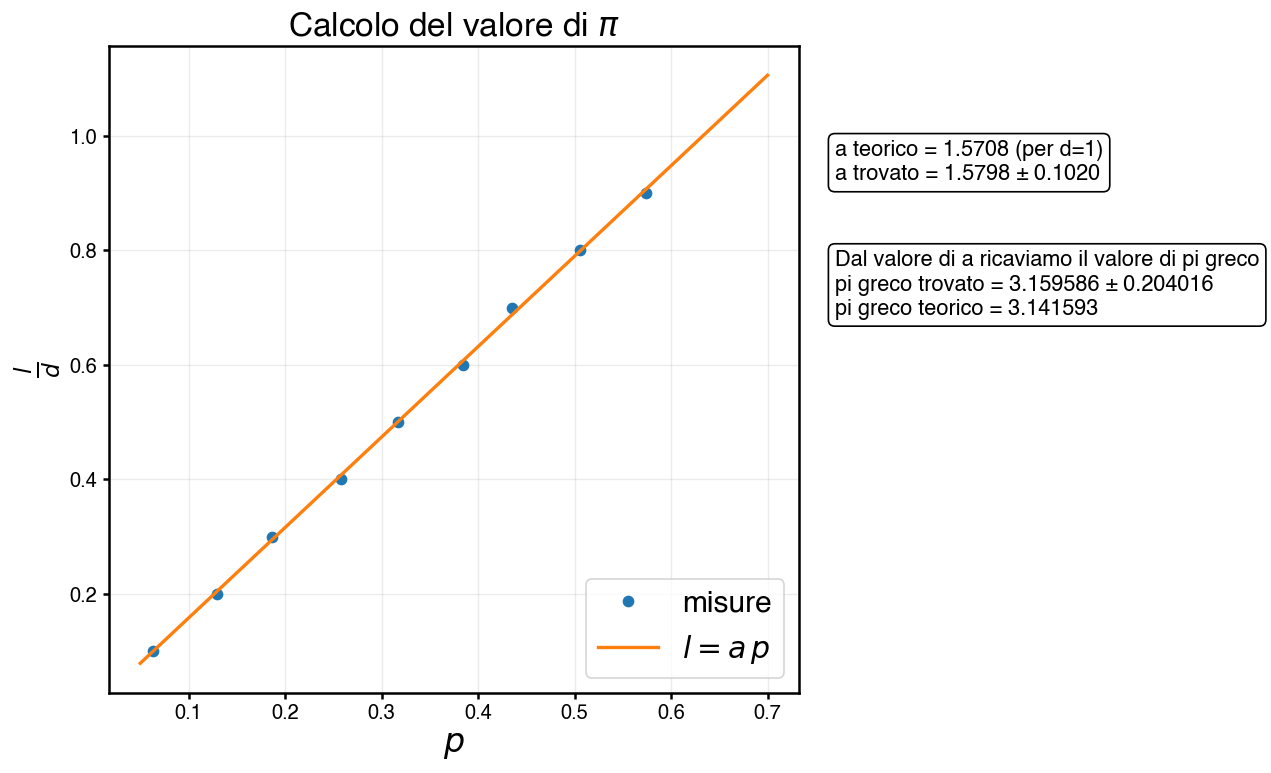

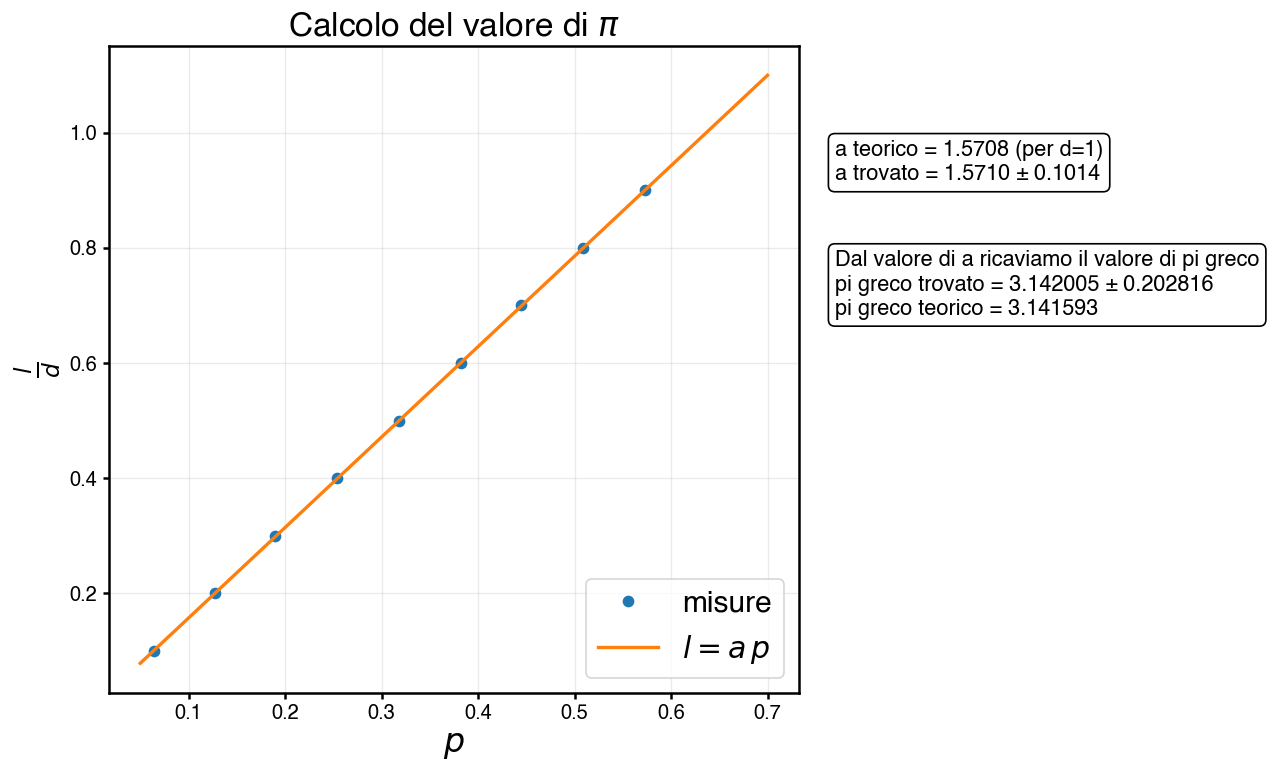

Tempo totale (toc): 1.017 s per Ns=[100, 1000, 10000, 1000000]


In [5]:
import numpy as np
import matplotlib.pyplot as plt
import time
import matplotlib as mpl

# --- Stile globale: figure più grandi e testi leggibili ---
mpl.rcParams['figure.figsize'] = (10, 7)
mpl.rcParams['figure.dpi'] = 120
mpl.rcParams['savefig.dpi'] = 120
mpl.rcParams['font.family'] = ['Helvetica', 'DejaVu Sans']
mpl.rcParams['font.weight'] = 'bold'

# --- "tic" ---
t0 = time.perf_counter()

# Parametri come nel MATLAB
l = np.arange(0.1, 1.0, 0.1)   # 0.1:0.1:0.9
d = 1.0
dl = 0.05 * np.ones_like(l)   # MATLAB usa uno scalare: qui lo espandiamo

# Lista di N
RUN_HEAVY = False  # metti True per includere N=1e8
Ns = [100, 1_000, 10_000, 1_000_000] + ([100_000_000] if RUN_HEAVY else [])

def plot_fit_for_N(fig_num, p, l, d, pout, dp):
    """Replica del plot MATLAB per un dato N, con layout robusto (no overlap)."""
    a, b = pout
    da, db = dp

    # Figura grande + spazio laterale per le textbox (come annotation MATLAB ma fuori dagli assi)
    fig, ax = plt.subplots(num=fig_num, figsize=(10, 7), dpi=120, clear=True)

    # Punti sperimentali
    ax.plot(p, l/d, 'o', linewidth=2, label='misure')

    # Retta di fit (MATLAB: fplot(pout(1)*x,[0.05 0.7]))
    p_fit = np.linspace(0.05, 0.7, 400)
    ax.plot(p_fit, (a * p_fit)/d, linewidth=2, label=r'$l = a\,p$')

    # Etichette/titolo (LaTeX)
    ax.set_xlabel(r'$p$', fontsize=20)
    ax.set_ylabel(r'$\frac{l}{d}$', fontsize=20)
    ax.set_title(r'Calcolo del valore di $\pi$', fontsize=20)

    # Stile assi
    ax.tick_params(width=1.5, labelsize=12)
    for spine in ax.spines.values():
        spine.set_linewidth(1.5)

    # Griglia leggera
    ax.grid(alpha=0.25)

    # Legenda senza sovrapposizioni
    ax.legend(loc='lower right', fontsize=18, frameon=True)

    # --- Textbox: mettile fuori dagli assi per evitare accavallamenti ---
    # Spazio a destra per le box
    fig.subplots_adjust(right=0.70)

    # Box 1: confronto su a
    text_a = (
        f"a teorico = {np.pi/2:.4f} (per d=1)\n"
        f"a trovato = {a:.4f} ± {abs(da):.4f}"
    )
    fig.text(
        0.73, 0.72, text_a,
        fontsize=13,
        bbox=dict(boxstyle='round', facecolor='white', edgecolor='black')
    )

    # Box 2: stima di pi
    pi_est = 2 * a / d
    dpi_est = 2 * da / d
    text_pi = (
        "Dal valore di a ricaviamo il valore di pi greco\n"
        f"pi greco trovato = {pi_est:.6f} ± {dpi_est:.6f}\n"
        f"pi greco teorico = {np.pi:.6f}"
    )
    fig.text(
        0.73, 0.56, text_pi,
        fontsize=13,
        bbox=dict(boxstyle='round', facecolor='white', edgecolor='black')
    )

    plt.show()

# Esecuzione: calcolo p e fit per ciascun N e plotting
results = {}
for k, N in enumerate(Ns, start=1):
    p, pout, dp = buffon(N, l, d, dl=dl, seed=0)  # usa la funzione buffon definita sopra nel notebook
    results[N] = (p, pout, dp)
    plot_fit_for_N(k, p, l, d, pout, dp)

# --- "toc" ---
dt = time.perf_counter() - t0
print(f"Tempo totale (toc): {dt:.3f} s per Ns={Ns}")
